# C3: measured model progress and evaluation

PP1 notebook 2 of 2. Recompute saved comparisons, explain the remaining failures, and connect them to the [separate bug demo](../C3_live_demo.ipynb). These historical test results are already exposed; they must not be described as a fresh untouched final test.

In [1]:
from pathlib import Path
import sys
# Works when launched from the repository root, vision_oracle, or this folder.
candidates = [p / suffix for p in [Path.cwd(), *Path.cwd().parents]
              for suffix in ('', 'notebooks/old/pp1', 'vision_oracle/notebooks/old/pp1')]
HERE = next((p.resolve() for p in candidates if (p/'pp1_evidence.py').exists()), None)
if HERE is None:
    raise FileNotFoundError('Open from the repository or the pp1 notebook folder')
sys.path.insert(0, str(HERE))
from pp1_evidence import *
from IPython.display import display, Markdown
B = load_bundle(HERE)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
display(Markdown('**Mode: saved evidence / CPU only. No model downloads, training, or inference.**'))
print('Verified bundle checksum. Source files:', len(B['provenance']))


**Mode: saved evidence / CPU only. No model downloads, training, or inference.**

Verified bundle checksum. Source files: 41


## 1. Fair comparison checks
Pair records by full image identity and verify gold labels. Thresholds come only from validation, never the test-optimal threshold stored in score files. Scores are normalized true/false token logits, not calibrated probabilities.

In [2]:
table = score_table(B)
contracts = []
for name in RUNS:
    d = B['benchmarks'][name+'_test316_scores']
    c = d['meta']['contract']
    contracts.append(dict(run=name, n=len(d['records']), user_prompt=c.get('user_prompt'),
                          system_prompt=c.get('system_prompt'), pixels=c.get('image_max_pixels')))
display(pd.DataFrame(contracts).set_index('run'))
reference = B['benchmarks'][RUNS[0]+'_test316_scores']['records']
display(pd.crosstab(pd.Series([source(r) for r in reference],name='source'),
                    pd.Series([r['gold_type'] for r in reference],name='gold class')))
print('All four runs have identical image identities and gold labels:', len(reference))


,n,user_prompt,system_prompt,pixels
run,,,,
base_v2prompt,316,Inspect this Android screen for non-crash UI d...,None,262144
v1_step246,316,Analyze this mobile screen for non-crash visua...,None,262144
v2_checkpoint-173,316,Inspect this Android screen for non-crash UI d...,None,262144
v2_epoch2,316,Inspect this Android screen for non-crash UI d...,None,262144


gold class,component_overlap,data_binding_null,missing_component,none,text_truncation
source,,,,,
OwlEye,31,15,22,83,15
Rico clean,0,0,0,75,0
Rico mutation,31,0,21,0,23


All four runs have identical image identities and gold labels: 316


## 2. Base versus fine-tuned recipes
The base/v2 prompt is shared; v1 uses its own training prompt. The v1 comparison therefore includes both weights and input-contract differences. Report precision and recall together: detecting almost every defect can still flag many clean screens.

,val_auc,test_auc,threshold,accuracy,precision,recall,f1,tp,fp,fn,tn
run,,,,,,,,,,,
base_v2prompt,0.5951,0.5734,0.1801,0.5127,0.5064,1.0000,0.6723,158,154,0,4
v1_step246,0.7369,0.7504,0.5351,0.6456,0.6127,0.7911,0.6906,125,79,33,79
v2_checkpoint-173,0.7071,0.6799,0.2282,0.5728,0.5434,0.9114,0.6809,144,121,14,37
v2_epoch2,0.7088,0.7124,0.1801,0.5759,0.5438,0.9430,0.6898,149,125,9,33


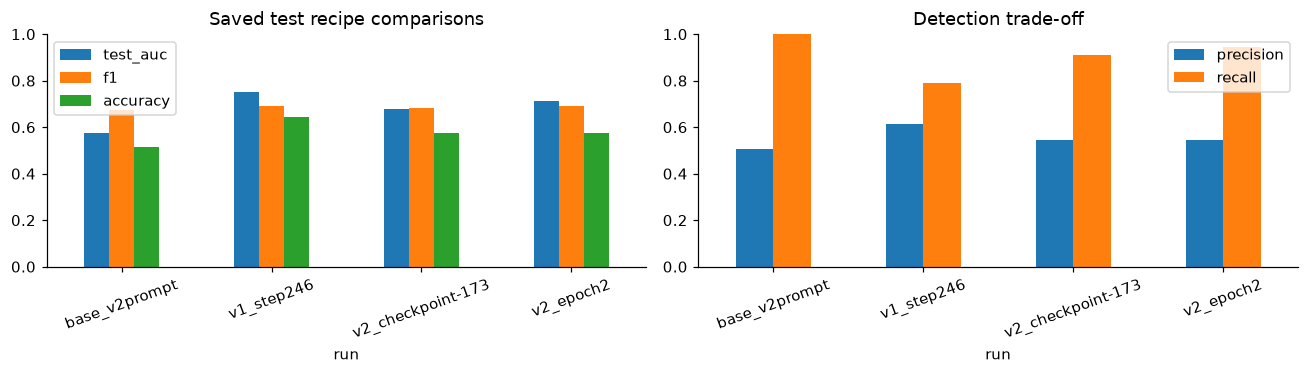

In [3]:
display(table[['val_auc','test_auc','threshold','accuracy','precision','recall','f1','tp','fp','fn','tn']].round(4))
fig, axes = plt.subplots(1,2,figsize=(12,3.5))
table[['test_auc','f1','accuracy']].plot.bar(ax=axes[0],ylim=(0,1),rot=20)
table[['precision','recall']].plot.bar(ax=axes[1],ylim=(0,1),rot=20)
axes[0].set_title('Saved test recipe comparisons'); axes[1].set_title('Detection trade-off')
plt.tight_layout(); plt.show()


## 3. ROC and precision–recall curves
ROC summarizes ranking across thresholds. Precision–recall exposes false alarms when seeking high recall. Curves are recomputed from rounded stored scores with tied scores grouped together; no test threshold is selected.

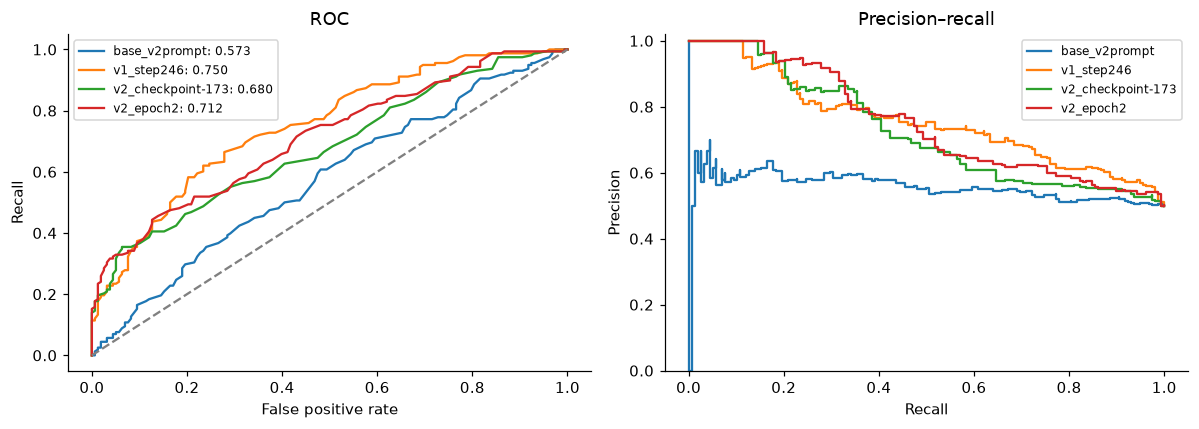

In [4]:
fig, axes = plt.subplots(1,2,figsize=(11,4))
for name in RUNS:
    records = B['benchmarks'][name+'_test316_scores']['records']
    fpr,tpr,precision,auc = curves(records)
    axes[0].plot(fpr,tpr,label=f'{name}: {auc:.3f}')
    axes[1].step(tpr,precision,where='post',label=name)
axes[0].plot([0,1],[0,1],'--',color='gray')
axes[0].set(xlabel='False positive rate',ylabel='Recall',title='ROC')
axes[1].set(xlabel='Recall',ylabel='Precision',title='Precision–recall',ylim=(0,1.02))
for ax in axes: ax.legend(fontsize=8)
plt.tight_layout(); plt.show()


## 4. Confusions and paired progress
Count which exact screens become correct and which regress. A paired bootstrap estimates uncertainty in accuracy change over these saved screens; correlated screens from the same app can make image-level intervals optimistic.

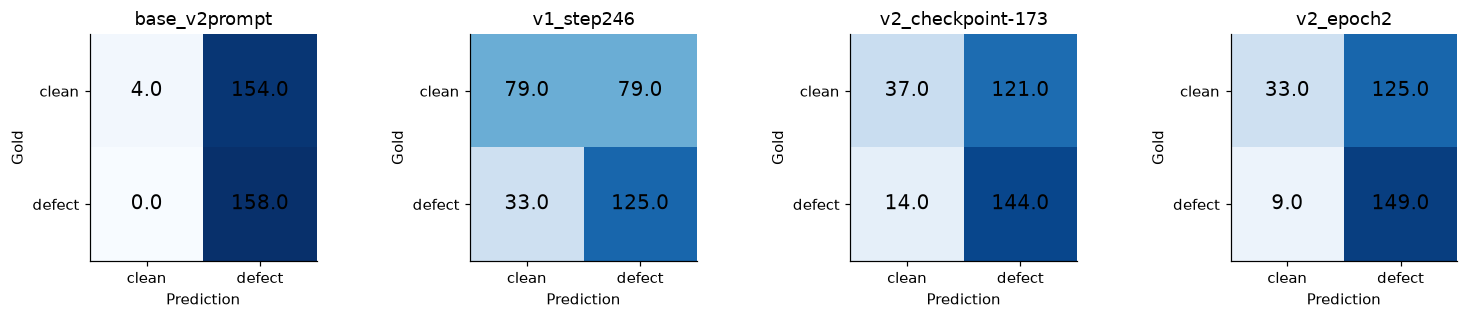

,repaired,regressed,accuracy_change,ci95_low,ci95_high
recipe,,,,,
v1_step246,76,34,0.1329,0.0696,0.1962
v2_checkpoint-173,35,16,0.0601,0.0158,0.1076
v2_epoch2,31,11,0.0633,0.0222,0.1013


In [5]:
fig, axes = plt.subplots(1,4,figsize=(14,3))
for ax,name in zip(axes,RUNS): confusion_plot(ax,table.loc[name],name)
plt.tight_layout(); plt.show()
def correct(name):
    rr = aligned(reference,B['benchmarks'][name+'_test316_scores']['records'])
    return np.array([(r['p_defect'] >= table.loc[name,'threshold']) == r['gold_has'] for r in rr])
baseline = correct(RUNS[0]); rng = np.random.default_rng(42)
rows=[]
for name in RUNS[1:]:
    now=correct(name); delta=now.astype(int)-baseline.astype(int)
    boot=delta[rng.integers(0,len(delta),size=(2000,len(delta)))].mean(axis=1)
    lo,hi=np.quantile(boot,[.025,.975])
    rows.append(dict(recipe=name, repaired=int(sum(now & ~baseline)), regressed=int(sum(~now & baseline)),
                     accuracy_change=delta.mean(), ci95_low=lo, ci95_high=hi))
display(pd.DataFrame(rows).set_index('recipe').round(4))


## 5. Actual full-output backend decisions
Score-only results and generated verdict/type/box results are separate measurements. Two v1 decisions lie at the rounded threshold boundary; use the recorded full-output decisions for this section. Invalid results are kept explicit, never counted as clean.

,n,tp,fp,fn,tn,invalid,coverage,accuracy,precision,recall,f1
v1 full output,316,124,78,34,80,0,1.0,0.6456,0.6139,0.7848,0.6889


,image,stored_score,recorded_prediction
0,D:/university/Resesarch/dataset/clean/13996.jpg,0.5351,False
1,C:/Games/OwlEye/Dataset/bug-aug/bug-aug/bug.41...,0.5351,False


Clean-screen false positive rate: 49.4%


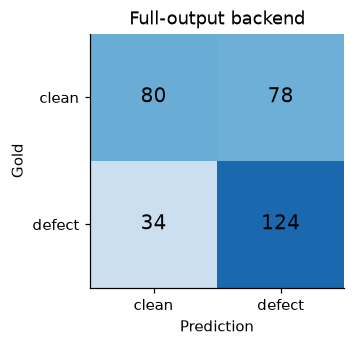

In [6]:
end = B['benchmarks']['final_test316_end_to_end']
rr = end['records']
full = binary_metrics([r['gold_has'] for r in rr],[r.get('pred_has') for r in rr])
display(pd.DataFrame([full],index=['v1 full output']).round(4))
score_rr = aligned(rr,B['benchmarks']['v1_step246_test316_scores']['records'])
boundary = [dict(image=r['image'],stored_score=s['p_defect'],recorded_prediction=r.get('pred_has'))
            for r,s in zip(rr,score_rr) if (s['p_defect'] >= table.loc['v1_step246','threshold']) != r.get('pred_has')]
display(pd.DataFrame(boundary))
print(f"Clean-screen false positive rate: {full['fp']/(full['fp']+full['tn']):.1%}")
fig, ax=plt.subplots(figsize=(4,3)); confusion_plot(ax,full,'Full-output backend'); plt.show()


## 6. Which bugs are recognized?
Binary recall is not defect-type accuracy or localization quality. Report the number of examples per class. Type and box annotations have not been established as independently human-verified; treat these metrics as exploratory.

,n,binary_accuracy,type_accuracy
gold_type,,,
component_overlap,62,0.6935,0.5968
data_binding_null,15,1.0000,0.0667
missing_component,43,0.8837,0.4186
none,158,0.5063,0.5063
text_truncation,38,0.7368,0.0000


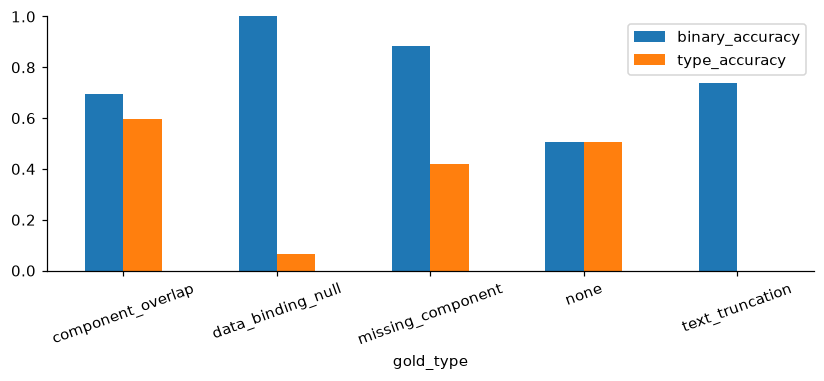

Predicted type,component_overlap,data_binding_null,missing_component,none
Gold type,,,,
component_overlap,37,1,5,19
data_binding_null,13,1,1,0
missing_component,20,0,18,5
none,66,0,12,80
text_truncation,21,1,6,10


IoU >= 0.5 / ALL gold defects: 13 / 158
Gold defects without a measured IoU: 34


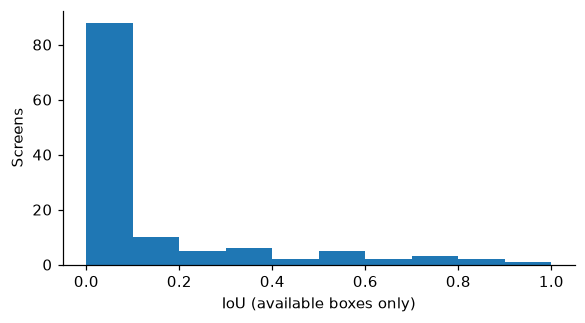

,n,tp,fp,fn,tn,invalid,coverage,accuracy,precision,recall,f1
source,,,,,,,,,,,
OwlEye,166,68,42,15,41,0,1.0,0.6566,0.6182,0.8193,0.7047
Rico clean,75,0,36,0,39,0,1.0,0.5200,0.0000,0.0000,0.0000
Rico mutation,75,56,0,19,0,0,1.0,0.7467,1.0000,0.7467,0.8550


In [7]:
rows=[]
for kind in sorted({r['gold_type'] for r in rr}):
    group=[r for r in rr if r['gold_type']==kind]
    rows.append(dict(gold_type=kind,n=len(group),
        binary_accuracy=sum(r.get('pred_has')==r['gold_has'] for r in group)/len(group),
        type_accuracy=sum(r.get('pred_type')==r['gold_type'] for r in group)/len(group)))
classes=pd.DataFrame(rows).set_index('gold_type'); display(classes.round(4))
classes[['binary_accuracy','type_accuracy']].plot.bar(figsize=(9,3),ylim=(0,1),rot=20); plt.show()
display(pd.crosstab(pd.Series([r['gold_type'] for r in rr],name='Gold type'),
                    pd.Series([r.get('pred_type') or 'INVALID' for r in rr],name='Predicted type')))
defects=[r for r in rr if r['gold_has']]
valid_iou=[r['iou'] for r in defects if r.get('iou') is not None]
print('IoU >= 0.5 / ALL gold defects:', sum(r.get('iou') is not None and r['iou']>=.5 for r in defects), '/', len(defects))
print('Gold defects without a measured IoU:', len(defects)-len(valid_iou))
fig,ax=plt.subplots(figsize=(6,3)); ax.hist(valid_iou,bins=np.linspace(0,1,11))
ax.set(xlabel='IoU (available boxes only)',ylabel='Screens'); plt.show()
source_rows=[]
for name in sorted({source(r) for r in rr}):
    group=[r for r in rr if source(r)==name]
    source_rows.append(dict(source=name,**binary_metrics([r['gold_has'] for r in group],[r.get('pred_has') for r in group])))
display(pd.DataFrame(source_rows).set_index('source').round(4))


## 7. Evidence that the inference contract mattered
Pair the same diagnostic screens before/after the input repair. Prompt and image resolution changed together; this is a joint input-contract ablation, not evidence that only one setting caused the improvement. Small validation diagnostic, not final-test accuracy.

,n,tp,fp,fn,tn,invalid,coverage,accuracy,precision,recall,f1
contract,,,,,,,,,,,
old app input,18,1,1,10,6,0,1.0,0.3889,0.5000,0.0909,0.1538
training input,18,9,5,2,2,0,1.0,0.6111,0.6429,0.8182,0.7200


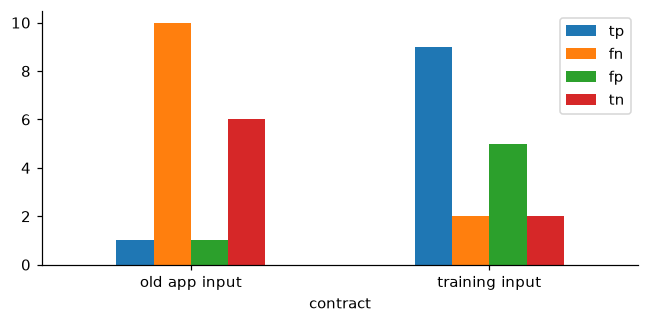

In [8]:
old=B['diagnosis']['v1_adapter_app_input_val18']
new=B['diagnosis']['v1_adapter_training_input_val60']
lookup={identity(r):r for r in new}
paired=aligned(old,[lookup[identity(r)] for r in old])
diagnosis=pd.DataFrame([dict(contract=label,**binary_metrics([r['gold_has'] for r in rows],[r.get('pred_has') for r in rows]))
                       for label,rows in [('old app input',old),('training input',paired)]]).set_index('contract')
display(diagnosis.round(4))
diagnosis[['tp','fn','fp','tn']].plot.bar(figsize=(7,3),rot=0); plt.show()


## 8. Tiling and practical cost
Validation tiling can increase recall while adding false alarms and latency. Backend latency includes generation but does not establish complete camera/UI/API latency. Score-only timing is not full inspection timing.

,n,tp,fp,fn,tn,invalid,coverage,accuracy,precision,recall,f1,median_seconds
policy,,,,,,,,,,,,
global_only,60,22,15,6,17,0,1.0,0.6500,0.5946,0.7857,0.6769,5.4695
global_plus_tiles_v1,60,28,29,0,3,0,1.0,0.5167,0.4912,1.0000,0.6588,19.3038


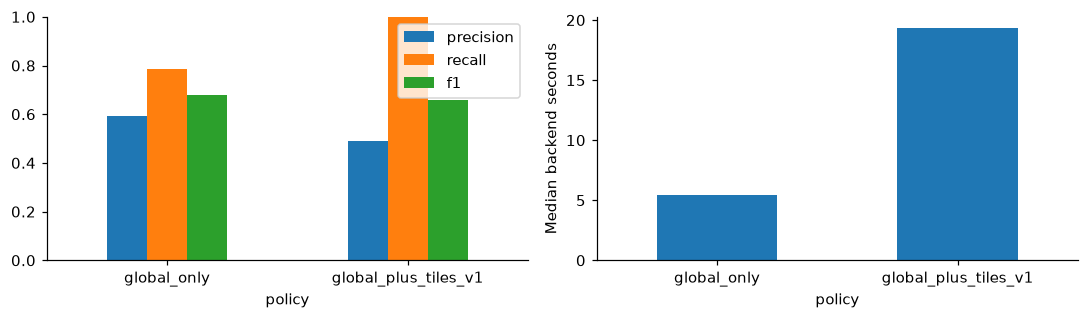

,n,median_seconds,p95_seconds,saved_peak_vram_GiB,load_seconds
0,316,8.03545,24.234775,1.709473,47.0


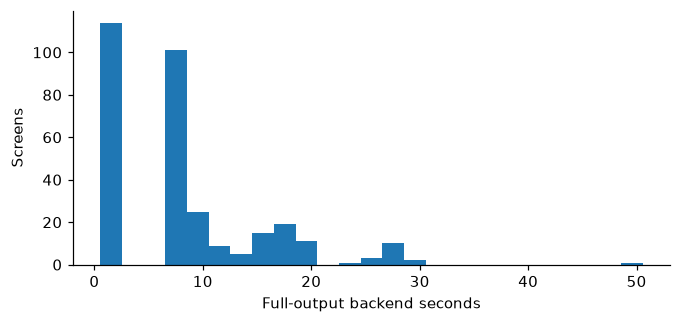

In [9]:
tile_rows=[]
for name,policy in B['tiles']['policies'].items():
    records=policy['records']
    tile_rows.append(dict(policy=name,**binary_metrics([r['gold_has'] for r in records],[r.get('pred_has') for r in records]),
                          median_seconds=np.median([r['latency_ms'] for r in records])/1000))
tiles=pd.DataFrame(tile_rows).set_index('policy'); display(tiles.round(4))
fig,axes=plt.subplots(1,2,figsize=(10,3))
tiles[['precision','recall','f1']].plot.bar(ax=axes[0],ylim=(0,1),rot=0)
tiles['median_seconds'].plot.bar(ax=axes[1],rot=0,ylabel='Median backend seconds')
plt.tight_layout(); plt.show()
lat=np.array([r['latency_ms'] for r in rr])/1000
display(pd.DataFrame([dict(n=len(lat),median_seconds=np.median(lat),p95_seconds=np.percentile(lat,95),
                          saved_peak_vram_GiB=end['peak_vram_bytes']/1024**3,
                          load_seconds=end['meta']['load_seconds'])]))
fig,ax=plt.subplots(figsize=(7,3)); ax.hist(lat,bins=25); ax.set(xlabel='Full-output backend seconds',ylabel='Screens'); plt.show()


## 9. Honest case studies
These are deterministic examples from the saved full-output run: first true positive, false positive, false negative and true negative. The table executes without external images. Use the live demo notebook for screenshot overlays and bug demonstrations; show a failure as well as a success.

In [10]:
examples=[]
for gold,pred,label in [(True,True,'TP'),(False,True,'FP'),(True,False,'FN'),(False,False,'TN')]:
    r=next((r for r in rr if r['gold_has'] is gold and r.get('pred_has') is pred),None)
    if r: examples.append(dict(outcome=label,image=r['image'],gold_type=r['gold_type'],
                              predicted_type=r['pred_type'],gold_box=r['gold_box'],predicted_box=r['pred_box'],iou=r['iou']))
display(pd.DataFrame(examples).set_index('outcome'))


,image,gold_type,predicted_type,gold_box,predicted_box,iou
outcome,,,,,,
TP,C:/Games/OwlEye/Dataset/bug-aug/bug-aug/bug.44...,component_overlap,component_overlap,"[280, 40, 600, 940]","[220, 10, 520, 950]",0.6102
FP,D:/university/Resesarch/dataset/clean/13207.jpg,none,missing_component,None,"[44, 0, 131, 1000]",NaN
FN,D:/university/Resesarch/dataset/mutated_bugs/1...,text_truncation,none,"[940, 711, 995, 929]",None,NaN
TN,D:/university/Resesarch/dataset/clean/10036.jpg,none,none,None,None,NaN


## 10. Dataset progress is separate from model progress
The v3 report documents new data preparation and app grouping. It is not a v3 model evaluation. Human review of defect visibility/type/boxes and a new frozen app-disjoint holdout are needed before stronger generalization claims.

,train,val,test
rico_clean|none,700,110,110
rico_mutated|component_overlap,250,38,38
rico_mutated|data_binding_null,250,37,37
rico_mutated|missing_component,250,37,37
rico_mutated|text_truncation,250,38,38
owleye_bug|component_overlap,0,26,29
owleye_bug|data_binding_null,0,23,20
owleye_bug|missing_component,0,14,26
owleye_bug|text_truncation,0,19,7
owleye_normal|none,0,82,83


train    1700
val       424
test      425
Name: screens per split, dtype: int64

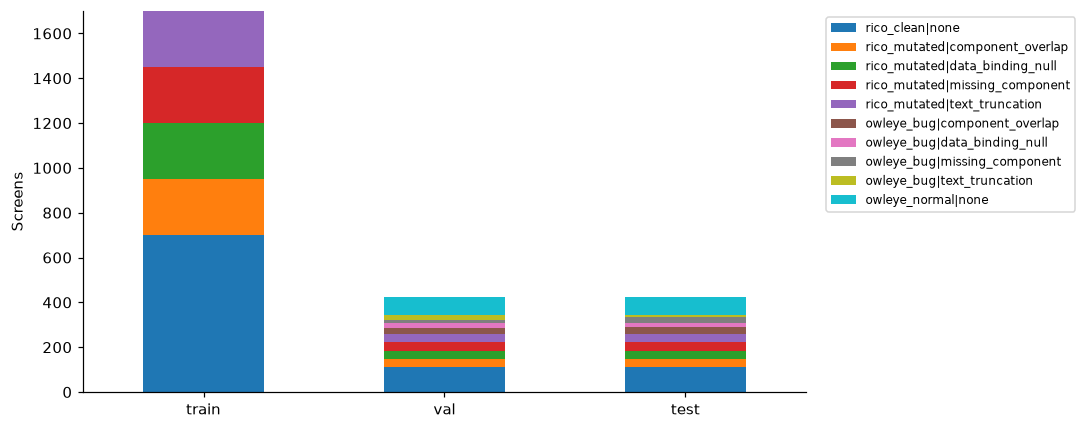

Reported app groups: 1322
Unlabelled OwlEye bugs excluded: 386


In [11]:
splits=pd.DataFrame(B['v3']['splits']).fillna(0).astype(int)
display(splits); display(splits.sum().rename('screens per split'))
splits.T.plot.bar(stacked=True,figsize=(10,4),rot=0,ylabel='Screens')
plt.legend(bbox_to_anchor=(1.02,1),loc='upper left',fontsize=8); plt.tight_layout(); plt.show()
print('Reported app groups:', B['v3']['app_groups'])
print('Unlabelled OwlEye bugs excluded:', B['v3']['owleye_bug_unlabelled_excluded'])


## 11. Next experiments and panel conclusion
1. Run base and v1 under the **same exact contract** on validation; save full-precision scores, raw output and explicit invalid/abstention status.
2. For learning rate, hold initialization, dataset, split, rank, dropout, total steps and preprocessing fixed; compare 2e-5/5e-5/1e-4 on validation. Use a fixed stratified screening subset, then confirm finalists on full validation.
3. Test rank separately with the same controls and multiple seeds; report adapter size, memory, time and quality.
4. Human-review labels and freeze a fresh app-disjoint final holdout before the next model-selection cycle.
5. Evaluate hierarchy fusion only after a trained v3 checkpoint exists, with screenshot-only versus screenshot-plus-hierarchy controls.

**Defensible conclusion:** adapter training and input-contract repair produced measurable recipe-level progress. The saved newest model does not dominate the older v1 recipe. False positives, type prediction and localization remain substantial weaknesses. No new base inference or training was performed by these notebooks.

In [12]:
display(provenance(B))

,role,source,sha256,bytes
0,prior audit,D:\university\Resesarch\J26-SE-334\vision_orac...,dd4058fee921244cb5c3305d881946c6672b122247b974...,15421
1,tensor header (not weight content),D:\university\Resesarch\J26-SE-334\vision_orac...,7c0fed2cf13bde1906b514199f0e352183b949d24cce47...,73808
2,tensor header (not weight content),D:\university\Resesarch\J26-SE-334\vision_orac...,7692718763e900aed935798025815d45789769dbcef806...,5744
3,base architecture,D:\university\Resesarch\J26-SE-334\vision_orac...,422adefa19e62dd175961cec85bc0400344fe5bf9b22bd...,1196
4,tensor header (not weight content),D:\university\Resesarch\results\c3_lora_clean_...,120104a723728c3e7306f9bcbd77add2528563b72eb52a...,57912
5,v1_stage1 adapter config,D:\university\Resesarch\results\c3_lora_clean_...,c4ab6e9fb369c2e70991f5d061a5d4553616ef1799b756...,1264
6,v1_stage1 training state,D:\university\Resesarch\results\c3_lora_clean_...,20d81217abd6342913df6768d15cd498cc80c4f85027ee...,7953
7,tensor header (not weight content),D:\university\Resesarch\J26-SE-334\vision_orac...,120104a723728c3e7306f9bcbd77add2528563b72eb52a...,57912
8,v1_step246 adapter config,D:\university\Resesarch\J26-SE-334\vision_orac...,5efef80882bcdbe9ca4240cd0d2451d253e1734021464a...,1264
9,v1_step246 training state,D:\university\Resesarch\J26-SE-334\vision_orac...,8288d3fdfcab764a6e31443a6be686335d46ab60773261...,5666
